# NOAA Tides & Currents - 시간별 조위(hourly water level) 시계열 예측 실습

> **학습목표**
>
- NOAA 공개 API에서 시간별 조위 데이터를 직접 수집한다.
- 데이터 정합성을 확인한 뒤 시계열 패턴을 시각화한다.
- train / validation / test를 시간 순서대로 분리해 예측 모델을 비교한다.
- Seasonal Naive, AutoReg, SARIMA 중 최종 모델을 선택한다.


## 0) 데이터 설명
- **데이터 출처**: NOAA Tides & Currents API
- **관측소**: San Francisco (`9414290`)
- **변수**: 시간별 조위(`hourly_height`)
- **기간**: 2025-01-01 ~ 2025-12-31
- **단위**: meter, 기준면 `MLLW`

이 실습은 1년치 시간별 조위 데이터를 사용한다. 조석은 강한 반복 구조를 가지므로 시계열 예측 예제로 적합하다.


## 실행 안내
1. 위에서 아래로 순서대로 실행한다.
2. NOAA API 호출이 있으므로 인터넷 연결이 필요하다.
3. 핵심 결과는 `validation_results`, `test_results`에서 확인한다.
4. 최종 선택 모델은 마지막 요약 셀에서 확인한다.


In [1]:
import importlib.util
import subprocess
import sys

required = {
    'requests': 'requests',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'statsmodels': 'statsmodels',
    'sklearn': 'scikit-learn',
}
missing = [pip_name for module_name, pip_name in required.items() if importlib.util.find_spec(module_name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

In [2]:
import warnings
warnings.filterwarnings('ignore')

import math
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = (12, 4)

## 1) API 설정

In [3]:
BASE_URL = 'https://api.tidesandcurrents.noaa.gov/api/prod/datagetter'

STATION = {
    'id': '9414290',
    'name': 'San Francisco',
}

BEGIN_DATE = '20250101'
END_DATE = '20251231'
PRODUCT = 'hourly_height'
DATUM = 'MLLW'
TIME_ZONE = 'gmt'
UNITS = 'metric'
FMT = 'json'

SEASONAL_PERIOD = 12
AUTOREG_LAG_CANDIDATES = [24, 48, 72, 96, 168]
SARIMA_ORDER = (2, 0, 1)
SARIMA_SEASONAL_ORDER = (1, 0, 0, SEASONAL_PERIOD)

VALID_START = '2025-10-01 00:00'
TEST_START = '2025-12-01 00:00'
ZOOM_DAYS = 14
PACF_LAGS = 60

STATION

{'id': '9414290', 'name': 'San Francisco'}

In [4]:
def fetch_noaa_hourly_height(station_id: str,
                            begin_date: str,
                            end_date: str,
                            product: str = PRODUCT,
                            datum: str = DATUM,
                            time_zone: str = TIME_ZONE,
                            units: str = UNITS,
                            fmt: str = FMT) -> tuple[pd.DataFrame, dict]:
    params = {
        'product': product,
        'application': 'TimeSeriesAnalysis',
        'begin_date': begin_date,
        'end_date': end_date,
        'station': station_id,
        'datum': datum,
        'time_zone': time_zone,
        'units': units,
        'format': fmt,
    }

    r = requests.get(BASE_URL, params=params, timeout=30)
    r.raise_for_status()
    js = r.json()

    if 'data' not in js:
        raise ValueError(f'API 응답에 data가 없습니다: {js}')

    df = pd.DataFrame(js['data'])
    df['t'] = pd.to_datetime(df['t'], errors='coerce')
    df['water_level_m'] = pd.to_numeric(df['v'], errors='coerce').astype('float32')
    df['sigma_m'] = pd.to_numeric(df['s'], errors='coerce').astype('float32')
    df = df[['t', 'water_level_m', 'sigma_m']].dropna(subset=['t'])
    df = df.set_index('t').sort_index()
    return df, js.get('metadata', {})

## 2) 데이터 수집 및 구조 점검

In [5]:
df, meta = fetch_noaa_hourly_height(STATION['id'], BEGIN_DATE, END_DATE)

print('station :', meta.get('name'), meta.get('id'))
print('lat/lon :', meta.get('lat'), meta.get('lon'))
print('rows    :', len(df))
print('period  :', df.index.min(), '->', df.index.max())

df.head()

station : San Francisco 9414290
lat/lon : 37.8063 -122.4659
rows    : 8760
period  : 2025-01-01 00:00:00 -> 2025-12-31 23:00:00


,water_level_m,sigma_m
t,,
2025-01-01 00:00:00,0.035,0.052
2025-01-01 01:00:00,-0.269,0.046
2025-01-01 02:00:00,-0.343,0.042
2025-01-01 03:00:00,-0.295,0.042
2025-01-01 04:00:00,-0.015,0.046


In [6]:
# 원시 인덱스를 1시간 간격으로 고정한다.
full_index = pd.date_range(df.index.min(), df.index.max(), freq='h')
y_raw = df['water_level_m'].reindex(full_index)
sigma_raw = df['sigma_m'].reindex(full_index)

print('expected hourly rows:', len(full_index))
print('observed rows       :', len(df))
print('missing values      :', int(y_raw.isna().sum()))

y_raw.head()

expected hourly rows: 8760
observed rows       : 8760
missing values      : 0


2025-01-01 00:00:00    0.035
2025-01-01 01:00:00   -0.269
2025-01-01 02:00:00   -0.343
2025-01-01 03:00:00   -0.295
2025-01-01 04:00:00   -0.015
Freq: h, Name: water_level_m, dtype: float32

## 3) 데이터 정합성 검증

In [7]:
expected_delta = pd.Timedelta(hours=1)
intervals = df.index.to_series().diff().dropna()
missing_mask = y_raw.isna()

if missing_mask.any():
    groups = (missing_mask != missing_mask.shift()).cumsum()
    max_gap_steps = int(missing_mask.groupby(groups).sum().max())
else:
    max_gap_steps = 0

validation_report = pd.DataFrame({
    'value': [
        int(df.index.duplicated().sum()),
        int((intervals != expected_delta).sum()),
        int(missing_mask.sum()),
        round(float(missing_mask.mean() * 100), 3),
        max_gap_steps,
        round(max_gap_steps, 2),
    ]
}, index=[
    'duplicate_index_count',
    'non_hourly_interval_count',
    'missing_count',
    'missing_ratio_pct',
    'max_missing_gap_steps',
    'max_missing_gap_hours',
])

validation_report

,value
duplicate_index_count,0.0
non_hourly_interval_count,0.0
missing_count,0.0
missing_ratio_pct,0.0
max_missing_gap_steps,0.0
max_missing_gap_hours,0.0


In [8]:
# 2025 구간은 결측이 없지만, 짧은 결측이 생기는 경우를 대비해 보간 절차를 남겨둔다.
y = y_raw.interpolate(limit=6, limit_direction='both').astype('float32')

if y.isna().any():
    raise ValueError('보간 후에도 결측이 남아 있어 학습을 진행할 수 없습니다.')

print('final series length:', len(y))
print('remaining missing  :', int(y.isna().sum()))

final series length: 8760
remaining missing  : 0


## 4) 시각화

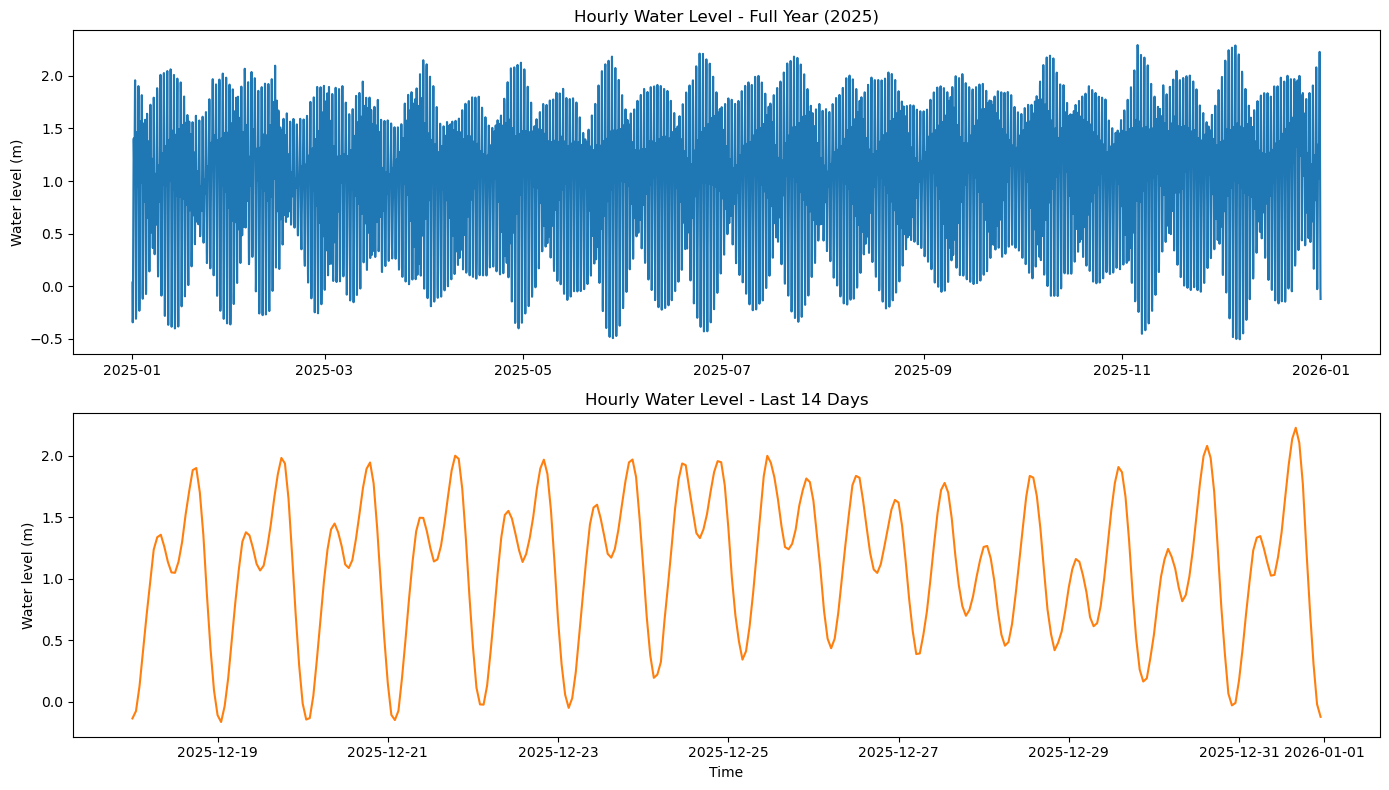

In [9]:
# 전체 1년 구간과 최근 14일 구간을 함께 본다.
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

axes[0].plot(y.index, y, color='tab:blue')
axes[0].set_title('Hourly Water Level - Full Year (2025)')
axes[0].set_ylabel('Water level (m)')

recent = y.last(f'{ZOOM_DAYS}D')
axes[1].plot(recent.index, recent, color='tab:orange')
axes[1].set_title(f'Hourly Water Level - Last {ZOOM_DAYS} Days')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Water level (m)')

plt.tight_layout()
plt.show()
plt.close('all')

In [10]:
# 월별 평균과 표준편차로 연중 수준 변화를 본다.
monthly_summary = y.resample('MS').agg(['mean', 'std', 'min', 'max'])
monthly_summary

,mean,std,min,max
2025-01-01,0.968515,0.579668,-0.401,2.061
2025-02-01,1.012318,0.524188,-0.275,2.096
2025-03-01,0.976646,0.523169,-0.152,2.148
2025-04-01,0.956086,0.541355,-0.400,2.124
2025-05-01,0.962132,0.574043,-0.493,2.182
2025-06-01,0.998312,0.576929,-0.429,2.211
2025-07-01,1.028862,0.554334,-0.338,2.182
2025-08-01,1.018680,0.526310,-0.211,2.031
2025-09-01,1.069811,0.512396,-0.053,2.016
2025-10-01,1.050536,0.521488,-0.093,2.191


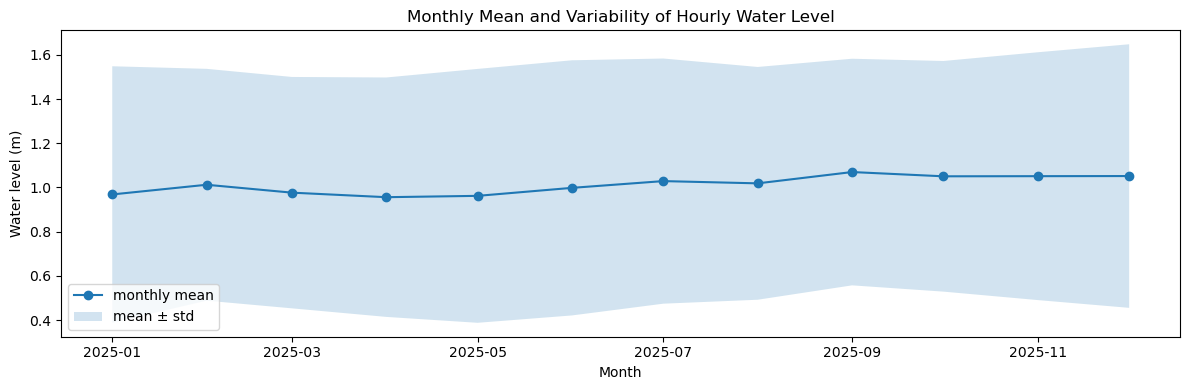

In [11]:
plt.figure(figsize=(12, 4))
plt.plot(monthly_summary.index, monthly_summary['mean'], marker='o', label='monthly mean')
plt.fill_between(
    monthly_summary.index,
    monthly_summary['mean'] - monthly_summary['std'],
    monthly_summary['mean'] + monthly_summary['std'],
    alpha=0.2,
    label='mean ± std',
)
plt.title('Monthly Mean and Variability of Hourly Water Level')
plt.xlabel('Month')
plt.ylabel('Water level (m)')
plt.legend()
plt.tight_layout()
plt.show()
plt.close('all')

## 5) STL / ACF / PACF 진단

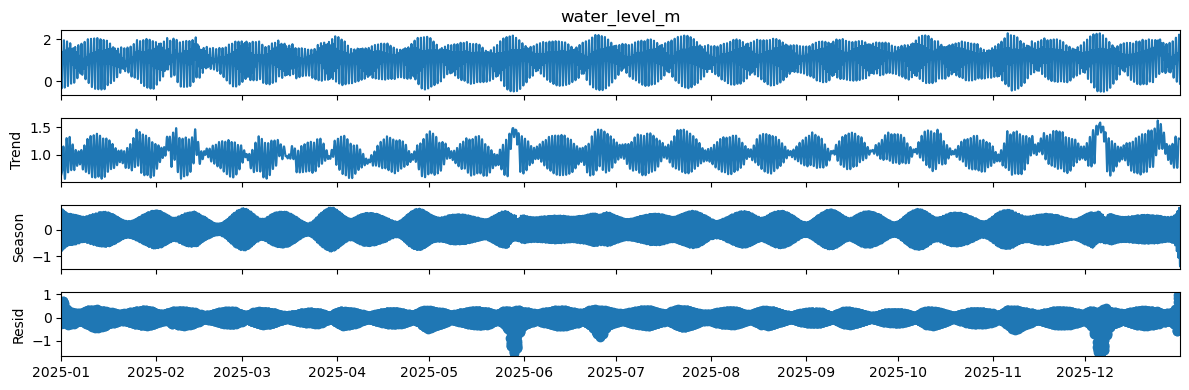

In [12]:
# 12시간 주기를 기준으로 반복 성분을 분리한다.
stl_result = STL(y, period=SEASONAL_PERIOD, robust=True).fit()
stl_result.plot()
plt.tight_layout()
plt.show()
plt.close('all')

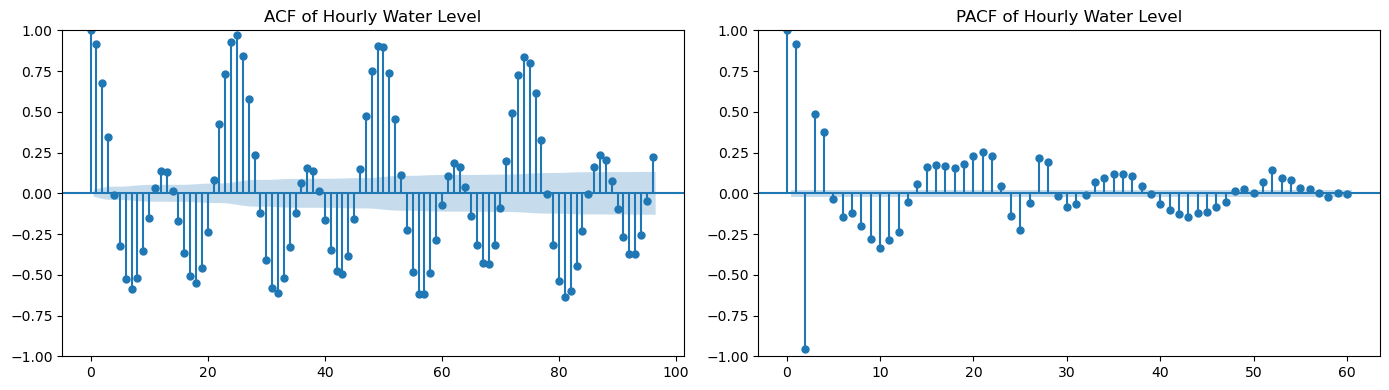

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y, lags=SEASONAL_PERIOD * 8, ax=axes[0])
plot_pacf(y, lags=PACF_LAGS, ax=axes[1], method='ywm')
axes[0].set_title('ACF of Hourly Water Level')
axes[1].set_title('PACF of Hourly Water Level')
plt.tight_layout()
plt.show()
plt.close('all')

## 6) Train / Validation / Test 분리

In [14]:
train = y.loc[:pd.Timestamp(VALID_START) - pd.Timedelta(hours=1)]
valid = y.loc[pd.Timestamp(VALID_START):pd.Timestamp(TEST_START) - pd.Timedelta(hours=1)]
test = y.loc[pd.Timestamp(TEST_START):]

split_table = pd.DataFrame([
    {'Split': 'Train', 'Start': train.index.min(), 'End': train.index.max(), 'Rows': len(train)},
    {'Split': 'Validation', 'Start': valid.index.min(), 'End': valid.index.max(), 'Rows': len(valid)},
    {'Split': 'Test', 'Start': test.index.min(), 'End': test.index.max(), 'Rows': len(test)},
])

split_table

,Split,Start,End,Rows
0,Train,2025-01-01,2025-09-30 23:00:00,6552
1,Validation,2025-10-01,2025-11-30 23:00:00,1464
2,Test,2025-12-01,2025-12-31 23:00:00,744


In [15]:
def eval_forecast(y_true: pd.Series, y_pred: pd.Series) -> dict:
    return {
        'RMSE': math.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred),
    }


def seasonal_naive_forecast(full_series: pd.Series,
                            target_index: pd.DatetimeIndex,
                            seasonal_period: int) -> pd.Series:
    pred = pd.Series(index=target_index, dtype='float64')
    for t in target_index:
        lag_t = t - pd.Timedelta(hours=seasonal_period)
        if lag_t in full_series.index:
            pred.loc[t] = full_series.loc[lag_t]
    return pred

## 7) Validation으로 모델 선택

In [16]:
validation_records = []
validation_predictions = {}

# 1) Seasonal Naive
valid_naive = seasonal_naive_forecast(y, valid.index, SEASONAL_PERIOD)
validation_predictions['Seasonal Naive'] = valid_naive
validation_records.append({
    'Model': 'Seasonal Naive',
    'Config': f'lag={SEASONAL_PERIOD}',
    **eval_forecast(valid, valid_naive),
})

# 2) AutoReg 후보 비교
for lag in AUTOREG_LAG_CANDIDATES:
    model = AutoReg(train, lags=lag, old_names=False, seasonal=False).fit()
    pred = model.predict(start=len(train), end=len(train) + len(valid) - 1, dynamic=False)
    pred.index = valid.index
    validation_predictions[f'AutoReg({lag})'] = pred
    validation_records.append({
        'Model': 'AutoReg',
        'Config': f'lags={lag}',
        **eval_forecast(valid, pred),
    })

# 3) SARIMA 비교
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sarima_valid_model = SARIMAX(
        train,
        order=SARIMA_ORDER,
        seasonal_order=SARIMA_SEASONAL_ORDER,
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False, maxiter=200)

sarima_valid_pred = sarima_valid_model.forecast(len(valid))
sarima_valid_pred.index = valid.index
validation_predictions['SARIMA'] = sarima_valid_pred
validation_records.append({
    'Model': 'SARIMA',
    'Config': f'{SARIMA_ORDER}x{SARIMA_SEASONAL_ORDER}',
    **eval_forecast(valid, sarima_valid_pred),
})

validation_results = pd.DataFrame(validation_records).sort_values('RMSE').reset_index(drop=True)
validation_results

,Model,Config,RMSE,MAE
0,AutoReg,lags=168,0.211783,0.169858
1,AutoReg,lags=96,0.281129,0.215259
2,AutoReg,lags=72,0.333676,0.255944
3,AutoReg,lags=48,0.417569,0.336892
4,AutoReg,lags=24,0.500449,0.419654
5,Seasonal Naive,lag=12,0.688851,0.579394
6,SARIMA,"(2, 0, 1)x(1, 0, 0, 12)",1.113442,0.973009


In [17]:
best_autoreg_row = validation_results[validation_results['Model'] == 'AutoReg'].iloc[0]
best_autoreg_lag = int(best_autoreg_row['Config'].split('=')[1])
selected_model_name = validation_results.iloc[0]['Model']
selected_model_config = validation_results.iloc[0]['Config']

print('best AutoReg lag :', best_autoreg_lag)
print('best validation model :', selected_model_name, selected_model_config)

best AutoReg lag : 168
best validation model : AutoReg lags=168


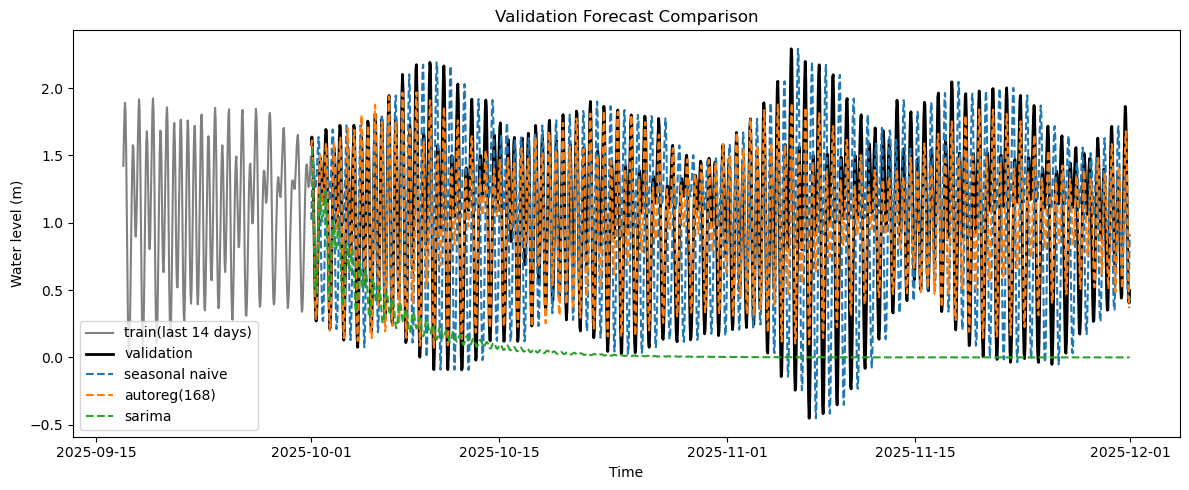

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(train.index[-14 * 24:], train.iloc[-14 * 24:], label='train(last 14 days)', color='gray')
plt.plot(valid.index, valid, label='validation', color='black', linewidth=2)
plt.plot(valid_naive.index, valid_naive, label='seasonal naive', linestyle='--')
plt.plot(validation_predictions[f'AutoReg({best_autoreg_lag})'].index,
         validation_predictions[f'AutoReg({best_autoreg_lag})'],
         label=f'autoreg({best_autoreg_lag})', linestyle='--')
plt.plot(sarima_valid_pred.index, sarima_valid_pred, label='sarima', linestyle='--')
plt.title('Validation Forecast Comparison')
plt.xlabel('Time')
plt.ylabel('Water level (m)')
plt.legend()
plt.tight_layout()
plt.show()
plt.close('all')

## 8) Test 구간 최종 평가

In [19]:
train_valid = y.loc[:pd.Timestamp(TEST_START) - pd.Timedelta(hours=1)]

test_naive = seasonal_naive_forecast(y, test.index, SEASONAL_PERIOD)

autoreg_final_model = AutoReg(train_valid, lags=best_autoreg_lag, old_names=False, seasonal=False).fit()
test_autoreg = autoreg_final_model.predict(start=len(train_valid), end=len(train_valid) + len(test) - 1, dynamic=False)
test_autoreg.index = test.index

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sarima_final_model = SARIMAX(
        train_valid,
        order=SARIMA_ORDER,
        seasonal_order=SARIMA_SEASONAL_ORDER,
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False, maxiter=200)

test_sarima = sarima_final_model.forecast(len(test))
test_sarima.index = test.index

test_results = pd.DataFrame([
    {'Model': 'Seasonal Naive', 'Config': f'lag={SEASONAL_PERIOD}', **eval_forecast(test, test_naive)},
    {'Model': 'AutoReg', 'Config': f'lags={best_autoreg_lag}', **eval_forecast(test, test_autoreg)},
    {'Model': 'SARIMA', 'Config': f'{SARIMA_ORDER}x{SARIMA_SEASONAL_ORDER}', **eval_forecast(test, test_sarima)},
]).sort_values('RMSE').reset_index(drop=True)

test_results

,Model,Config,RMSE,MAE
0,AutoReg,lags=168,0.169755,0.132069
1,Seasonal Naive,lag=12,0.824996,0.714302
2,SARIMA,"(2, 0, 1)x(1, 0, 0, 12)",1.095324,0.957290


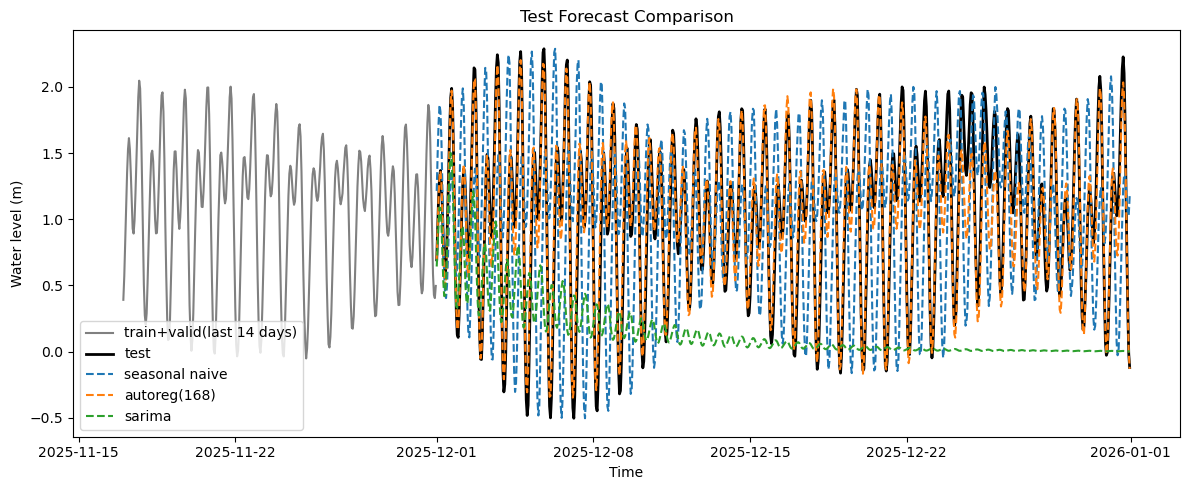

In [20]:
plt.figure(figsize=(12, 5))
plt.plot(train_valid.index[-14 * 24:], train_valid.iloc[-14 * 24:], label='train+valid(last 14 days)', color='gray')
plt.plot(test.index, test, label='test', color='black', linewidth=2)
plt.plot(test_naive.index, test_naive, label='seasonal naive', linestyle='--')
plt.plot(test_autoreg.index, test_autoreg, label=f'autoreg({best_autoreg_lag})', linestyle='--')
plt.plot(test_sarima.index, test_sarima, label='sarima', linestyle='--')
plt.title('Test Forecast Comparison')
plt.xlabel('Time')
plt.ylabel('Water level (m)')
plt.legend()
plt.tight_layout()
plt.show()
plt.close('all')

## 9) 요약

In [21]:
best_test_row = test_results.iloc[0]
summary_table = pd.DataFrame([
    {'항목': '데이터', '내용': 'NOAA San Francisco(9414290) 시간별 조위, 2025년 1년치'},
    {'항목': '정합성 검증', '내용': f"중복 {int(validation_report.loc['duplicate_index_count', 'value'])}건, 결측 {int(validation_report.loc['missing_count', 'value'])}건"},
    {'항목': '검증 방식', '내용': 'Train / Validation / Test 시간 분할'},
    {'항목': 'Validation 최적 모델', '내용': f"{selected_model_name} ({selected_model_config})"},
    {'항목': 'Test 최종 모델', '내용': f"{best_test_row['Model']} ({best_test_row['Config']})"},
    {'항목': 'Test RMSE', '내용': round(float(best_test_row['RMSE']), 4)},
    {'항목': 'Test MAE', '내용': round(float(best_test_row['MAE']), 4)},
])

summary_table

,항목,내용
0,데이터,"NOAA San Francisco(9414290) 시간별 조위, 2025년 1년치"
1,정합성 검증,"중복 0건, 결측 0건"
2,검증 방식,Train / Validation / Test 시간 분할
3,Validation 최적 모델,AutoReg (lags=168)
4,Test 최종 모델,AutoReg (lags=168)
5,Test RMSE,0.1698
6,Test MAE,0.1321


### 결론
- NOAA API에서 2025년 1년치 시간별 조위 데이터를 직접 수집했다.
- 중복, 시간 간격, 결측을 점검해 학습 가능한 시계열인지 확인했다.
- Train / Validation / Test를 시간 순서대로 분리해 모델을 평가했다.
- Validation에서는 여러 AutoReg 지연값과 SARIMA를 비교했고, 가장 낮은 오차를 보인 구성을 선택했다.
- Test 구간 최종 비교 결과를 바탕으로 NOAA 시간별 조위 예측에 가장 적합한 모델을 결정했다.
